<a href="https://colab.research.google.com/github/sauravpatil045/MLOPS1.THIRD-YEAR/blob/main/MIL8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
#pip install tensorflow matplotlib

In [32]:
# 1. Import Libraries
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [33]:
# 2. Load MNIST dataset
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (60000, 28, 28)
Testing data: (10000, 28, 28)


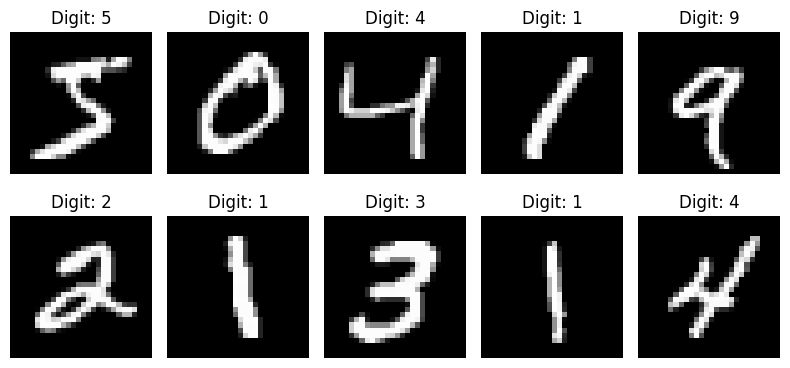

In [34]:
# 3. Display sample digit images
plt.figure(figsize=(8, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

In [35]:
# 4. Normalize pixel values from 6-255 to 0-1
x_train = x_train / 255.0
X_test = x_test / 255.0

In [36]:
# 5. Build a 3-Layer neural network
model = Sequential([
Flatten(input_shape=(28, 28)),
Dense(128, activation="relu"),
Dense(64, activation="relu"),
Dense(10, activation="softmax")])

In [37]:
model. summary ()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [38]:
model.compile(
optimizer="adam",
loss="sparse_categorical_crossentropy",
metrics=["accuracy"] )

In [39]:
history = model.fit(
x_train, y_train,
epochs=5,
batch_size=32,
validation_split=0.1 )

Epoch 1/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 2ms/step - accuracy: 0.9248 - loss: 0.2538 - val_accuracy: 0.9628 - val_loss: 0.1326
Epoch 2/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9668 - loss: 0.1088 - val_accuracy: 0.9708 - val_loss: 0.0931
Epoch 3/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9770 - loss: 0.0750 - val_accuracy: 0.9743 - val_loss: 0.0869
Epoch 4/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9809 - loss: 0.0590 - val_accuracy: 0.9752 - val_loss: 0.0919
Epoch 5/5
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9854 - loss: 0.0453 - val_accuracy: 0.9740 - val_loss: 0.0962


In [40]:
test_loss, test_accuracy = model.evaluate(x_test, y_test)
print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step - accuracy: 0.9704 - loss: 19.1885
Test Loss: 19.18846321105957
Test Accuracy: 0.9703999757766724


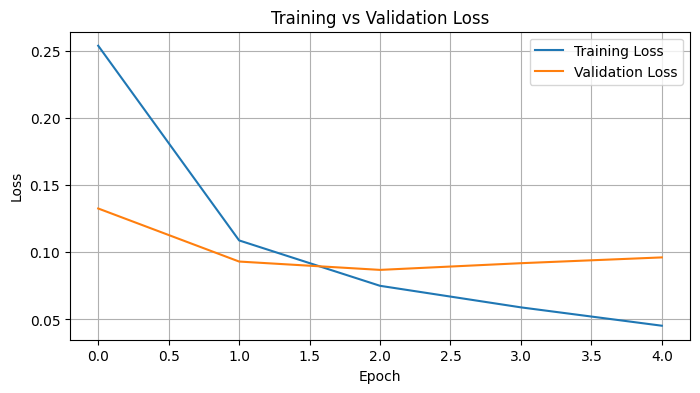

In [42]:
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()

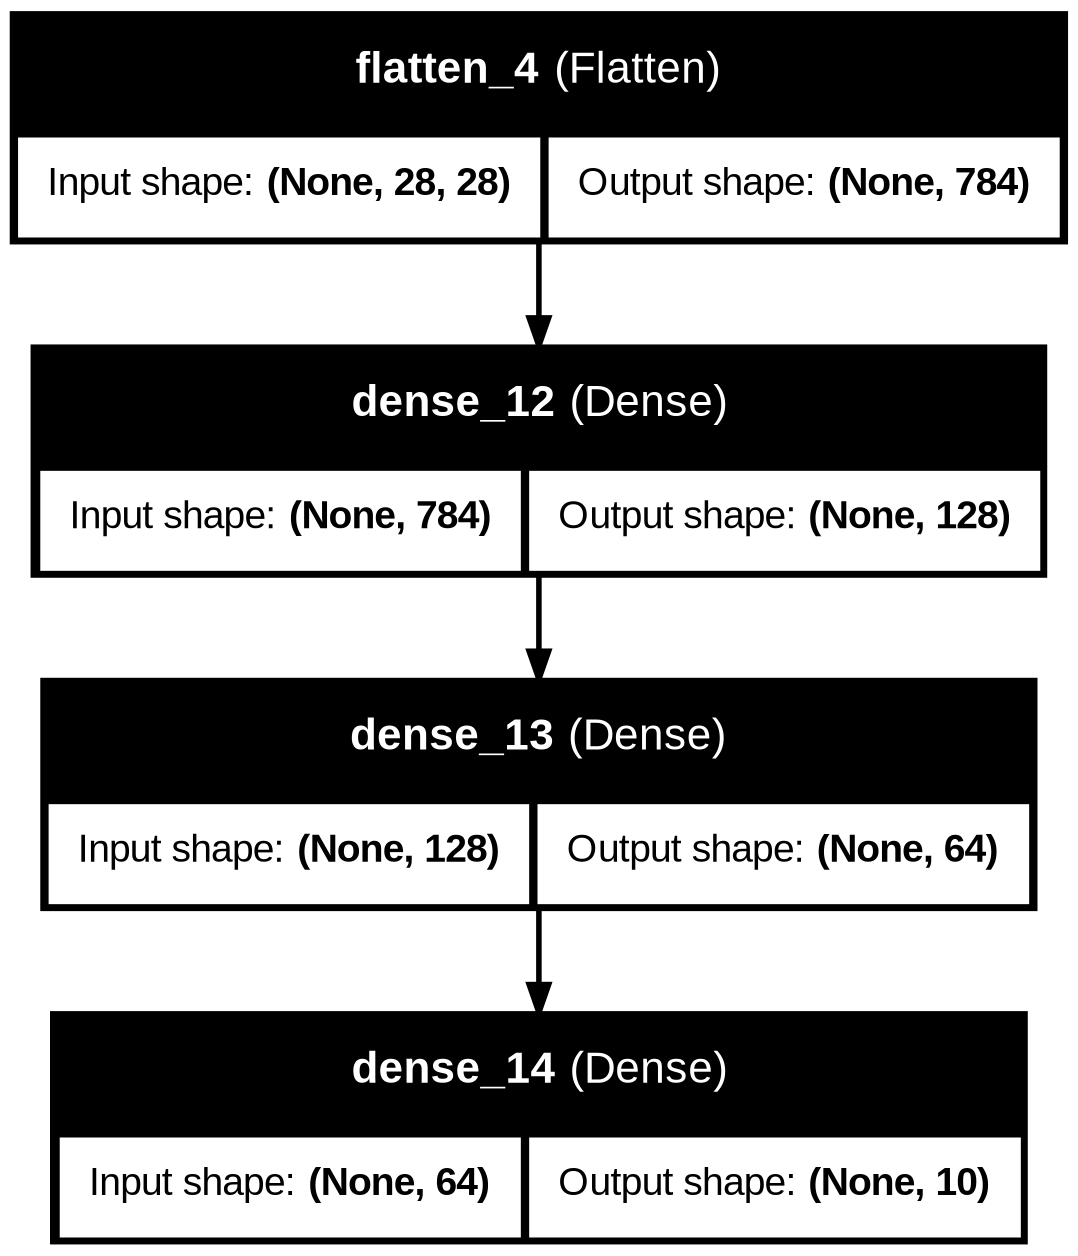

In [43]:
tf.keras.utils.plot_model(
model,
show_shapes=True,
show_layer_names=True,
to_file="dnn_architecture.png")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step


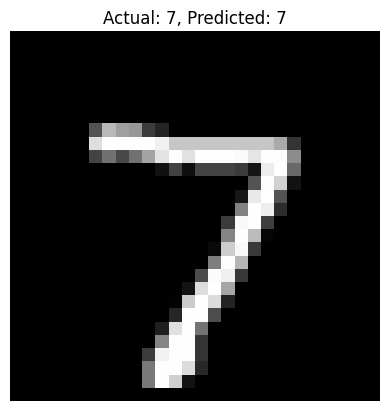

In [45]:
# 13. Predict a sample digit
predictions = model.predict(X_test[:1])
predicted_digit = np.argmax(predictions[0])
plt.imshow(x_test[0], cmap="gray")
plt.title(f"Actual: {y_test[0]}, Predicted: {predicted_digit}")
plt.axis("off")
plt.show()